### 4.2.2. 动态分支（Dynamic Branch）

- **定义**：节点的后续执行路径在 **运行时** 才确定，可以根据当前状态、输入数据或中间结果，动态决定要触发哪些下游任务或跳转到哪个下游节点。

特点：

- 下游**执行目标**可以在运行时选择；
- 下游**任务数量**可以在运行时决定；
- 可以为同一个下游节点动态创建多个执行任务；
- 适合实现 Map-Reduce 式动态扇出、多任务并行处理、运行时条件跳转等场景。

需要注意的是，所谓“动态”通常不是指运行时临时创建新的节点定义。节点本身一般仍需要在图编译前注册。动态性主要体现在：**运行时决定触发哪些节点，以及为这些节点创建多少个执行任务**。

创建动态分支的两种方法:
1. **`Send`**（动态扇出任务/数据）
2. **`Command(goto=...)`**（运行时跳转到下游节点）

> 运行时决定后续执行目标或任务数量 → 动态分支

#### 4.2.2.1 方式一: Send并行节点
**`Send`** 结合 **`add_conditional_edges()`** 使用，可以用于动态扇出任务

所谓**扇出（Fan-out）**，是指一个上游节点像扇子一样，向外分发出多个下游任务。

例如，根据一个主题，同时生成诗、词、笑话三个任务；又如，根据一个列表，为列表中的每个元素动态启动一个处理任务。

在代码方面，展现为路由函数可以返回一个 **`Send`** 实例序列，序列中每个实例都描述了一次独立的任务分发,这些任务通常会在同一个超步中并行执行。

- 分发到哪个下游节点；
- 给这个下游节点传入什么私有状态。

具体表现为:
```python
Send(
  self,
  /,
  node: str,
  arg: Any,
  *,
  timeout: float | timedelta | TimeoutPolicy | None = None
)
```

该构造器接收两个参数，并记录为实例属性：

- node：待启动的下游节点名称，必须是已在状态图中注册的合法名称
- arg：传递给下游节点的信息，仅对**`node`**指向的节点可见，通常应是私有状态。每个 **`Send`** 实例接收到的 **`arg`** 是独立的，互不相干。

{
    'poem': '《秋天》\n\n风把树梢染成金黄，  \n云在远山间慢慢游荡。  \n稻穗低头，田野飘香，  
\n一片落叶，写下季节的诗行。\n\n晚霞收起最后一抹暖光，  \n炊烟轻轻升向有星的夜空。  \n秋天不说告别，只把丰收  
\n和一轮明月，留在心上。',
    'ci_poem': '**《浣溪沙·秋日》**\n\n霜染疏林雁字斜，  \n一江秋水浸蒹葭，  \n西风吹瘦小楼花。  
\n\n客路无凭归梦远，  \n孤灯有影落窗纱，  \n一怀秋意付蒹葭。',
    'joke': '秋天为什么特别容易迷路？\n\n因为它总是在“枫”叶里找不到方向。'
}

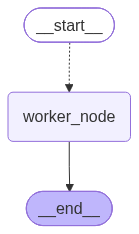

In [ ]:
from typing import TypedDict, Literal
from collections.abc import Sequence
from langgraph.graph import StateGraph, START, END
from langgraph.types import Send
from langchain.messages import HumanMessage
from langchain_deepseek import ChatDeepSeek
from langchain_openai import ChatOpenAI
import os
from rich import print as rprint
from dotenv import load_dotenv
# 从.env文件中加载环境变量
load_dotenv(override=True, verbose=True,dotenv_path="/Users/skk/Developer/lang-chain-learn/conf/.env")

OPENAI_API_KEY = os.environ["OPENAI_API_KEY"]
OPENAI_API_BASE = os.environ["OPENAI_API_BASE"]  # 与本项目 .env 中的名称一致
CONTENT_TYPES = ["poem", "ci_poem", "joke"]

model = ChatOpenAI(
    model="gpt-6-sol",  # 当前配置已验证可用；原 gpt-5.5 返回模型权限 403
    api_key=OPENAI_API_KEY,
    base_url=OPENAI_API_BASE,
)

class OverAllState(TypedDict):
    topic: str
    poem: str
    ci_poem: str
    joke: str

class WorkerState(TypedDict):
    """
    私有状态，只对 Worker 节点可用
    """
    content_type: Literal["poem", "ci_poem", "joke"]
    prompt: str

class InputState(TypedDict):
    topic: str

class OutputState(TypedDict):
    poem: str
    ci_poem: str
    joke: str

# state 存储动态节点的args
def worker_node(state: WorkerState) -> OutputState:
    content_type = state["content_type"]
    prompt = state["prompt"]

    content = model.invoke([HumanMessage(prompt)]).content
    return {
        content_type: content
    }# 最后是由返回值构成的字典

def router(state: InputState) -> Sequence[Send]:
    prompt = "请生成关于 {} 的 {}"
    english2chinese = {
        "poem": "一首诗",
        "ci_poem": "一首词",
        "joke": "一个笑话"
    }

    topic = state["topic"]
    # 建立send列表
    return [Send(
            "worker_node",
            {
                "content_type": content_type,
                "prompt": prompt.format(topic, english2chinese[content_type]),
            }
        ) for content_type in CONTENT_TYPES
    ]

builder = StateGraph(state_schema=OverAllState, input_schema=InputState, output_schema=OutputState)
builder.add_node("worker_node", worker_node)
builder.add_conditional_edges(
    START,
    router,
    path_map=["worker_node"]
)
builder.add_edge("worker_node", END)

graph = builder.compile()
res = graph.invoke({"topic": "秋天"})
rprint(res)

from IPython.display import display
display(graph)

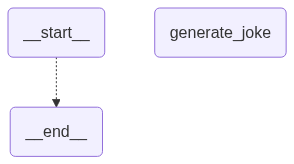

In [5]:
from typing import Annotated
from langgraph.types import Send
from langgraph.graph import END, START
from langgraph.graph import StateGraph
import operator
from typing import TypedDict

class OverallState(TypedDict):
    # 输入的主题列表，比如 ["cats", "dogs"]。普通字段，默认行为是覆盖（后写入的替换先写入的）。
    subjects: list[str]
    # 笑话列表。这里用 Annotated 给字段挂了 reducer operator.add，意思是：当多个节点（或多个并行分支）都往 jokes 里写数据时，用 operator.add（即列表 + 拼接）来合并，而不是覆盖。这正是后面多个并行 generate_joke 节点的结果能累加到同一个列表里的关键。
    jokes: Annotated[list[str], operator.add]

def continue_to_jokes(state: OverallState):
    # state["subjects"]：取出输入的主题列表（如 ["cats", "dogs"]）。
    # Send("generate_joke", {"subject": s})：为每个主题创建一个 Send 对象
    return [Send("generate_joke", {"subject": s}) for s in state["subjects"]]

builder = StateGraph(OverallState)
# builder.add_node(name, action)：注册一个名为 "generate_joke" 的节点，action 是该节点的处理函数。
# 这个函数没有使用 def 定义，而是使用了一个 lambda 表达式。这个 lambda 表达式接受一个 state 参数，并返回一个字典，其中包含一个键 "jokes"，其值是一个列表，包含一个字符串
builder.add_node("generate_joke", lambda state: {"jokes": [f"Joke about {state['subject']}"]})
builder.add_conditional_edges(START, continue_to_jokes)
builder.add_edge("generate_joke", END)
graph = builder.compile()

# Invoking with two subjects results in a generated joke for each
graph.invoke({"subjects": ["cats", "dogs"]})
# {'subjects': ['cats', 'dogs'], 'jokes': ['Joke about cats', 'Joke about dogs']}
display(graph)

因为 **`Send`** 的目标和数量可以运行时动态决定，图渲染器无法仅靠运行时返回值提前知道图结构。通过 **`path_map`** 声明候选下游节点后，渲染图才能正确展示 **`START`** 到 **`worker_node`** 的条件边关系。

补充说明：如果多个并行任务写入同一个状态字段，通常需要为该字段定义 reducer，用于合并多个任务的输出。本例中三个任务分别写入 **`poem`**、**`ci_poem`**、**`joke`** 三个不同字段，因此不会发生同一字段的并发合并问题。

#### 4.2.2.2 条件分支
##### Command介绍
**`Command`** 是 **`LangGraph`** 中用于控制图执行的多功能原语，它的构造器可以接受四个参数，并记录在同名类属性中：


```python
Command(
  self,
  *,
  graph: str | None = None,
  update: Any | None = None,
  resume: dict[str, Any] | Any | None = None,
  goto: Send | Sequence[Send | N] | N = ()
)
```

- **`update`**：更新图状态，效果等同于节点直接返回状态更新字典；
- **`goto`**：指定节点执行完成后的跳转目标，可用于运行时条件分支。当需要同时更新状态并控制跳转时，比单独使用条件边更合适；
- **`graph`**：存在子图时，用于指定跳转发生在哪一层图中，例如从子图跳转到父图；
- **`resume`**：用于恢复被中断的图执行，常见于 **`human-in-the-loop`** 场景。

##### 用`Command`实现条件分支
与 **`add_conditional_edges()`** 相比，**`Command`** 更适合“状态更新”和“控制流跳转”需要放在同一个节点返回值中的场景。

```python
return Command(
    update={"foo": "bar"},
    goto="next_node"
)
```

{
    'topic': '秋天',
    'content_type': 'poem',
    'poem': '**秋意**\n\n霜染疏林雁影斜  \n风摇落叶满天涯  \n一江秋水涵明月  \n半卷寒云入酒家'
}

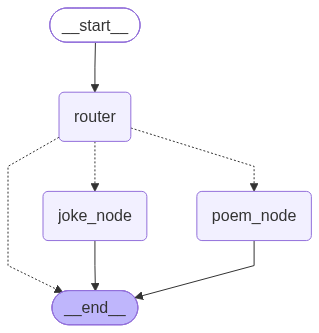

In [6]:
from typing import TypedDict, Literal
from collections.abc import Sequence
from langgraph.graph import StateGraph, START, END
from langgraph.types import Send,Command
from langchain.messages import HumanMessage
from langchain_deepseek import ChatDeepSeek
from langchain_openai import ChatOpenAI
import os
from rich import print as rprint
from dotenv import load_dotenv
# 从.env文件中加载环境变量
load_dotenv(override=True, verbose=True,dotenv_path="/Users/skk/Developer/lang-chain-learn/conf/.env")

OPENAI_API_KEY = os.environ["OPENAI_API_KEY"]
OPENAI_API_BASE = os.environ["OPENAI_API_BASE"]  # 与本项目 .env 中的名称一致
CONTENT_TYPES = ["poem", "ci_poem", "joke"]

model = ChatOpenAI(
    model="gpt-6-sol",  # 当前配置已验证可用；原 gpt-5.5 返回模型权限 403
    api_key=OPENAI_API_KEY,
    base_url=OPENAI_API_BASE,
)

class OverAllState(TypedDict):
    topic: str
    content_type: Literal["poem", "joke"]
    poem: str
    joke: str

class WorkerState(TypedDict):
    """
    私有状态，只对 Worker 节点可用
    """
    content_type: Literal["poem", "ci_poem", "joke"]
    prompt: str

class InputState(TypedDict):
    topic: str

class OutputState(TypedDict):
    poem: str
    ci_poem: str
    joke: str

def poem_node(state: OverAllState) -> OverAllState:
    topic = state["topic"]
    prompt = f"请生成一首关于 {topic} 的七言绝句"
    poem = model.invoke([HumanMessage(prompt)]).content

    return {
        "poem": poem
    }

def joke_node(state: OverAllState) -> OverAllState:
    topic = state["topic"]
    prompt = f"请生成一个关于 {topic} 的冷笑话"
    joke = model.invoke([HumanMessage(prompt)]).content

    return {
        "joke": joke
    }

def router(state: OverAllState) -> Command[Literal["poem_node", "joke_node", END]]:
    content_type = state["content_type"]

    if content_type == "poem":
        return Command (
            goto="poem_node"
        )
    elif content_type == "joke":
        return Command (
            goto="joke_node"
        )
    return Command (
        goto=END
    )


builder = StateGraph(state_schema=OverAllState)
builder.add_node("router", router)
builder.add_node("poem_node", poem_node)
builder.add_node("joke_node", joke_node)
builder.add_edge(START, "router")
builder.add_edge("poem_node", END)
builder.add_edge("joke_node", END)




graph = builder.compile()
res = graph.invoke({"topic": "秋天","content_type":"poem"})
rprint(res)

from IPython.display import display
display(graph)

{'topic': '秋天', 'content_type': 'none'}

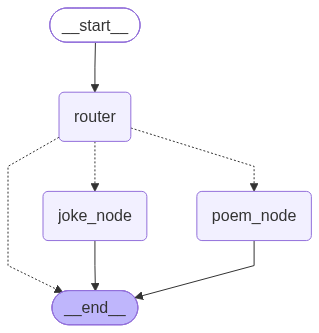

In [7]:
res = graph.invoke({"topic": "秋天","content_type":"none"})
rprint(res)

from IPython.display import display
display(graph)

当传入其他非法值时，跳转到 **`END`**，图直接结束。

```python
Command[Literal["poem_node", "joke_node", END]]
```
作为 **`router()`** 的返回值类型注解。注解只是便于图渲染时绘制，如果不声明，渲染出来的图可能无法正确表达 **`router`** 节点的潜在跳转关系。

需要注意的是，如果某个节点使用 **`Command(goto=...)`** 控制后续跳转，一般不要再给这个节点额外添加普通下游边。否则，普通边和 **`Command`** 指定的跳转都可能生效，导致多个下游节点被同时触发。

{
    'topic': '秋天',
    'content_type': 'none',
    'poem': '**《秋夜》**\n\n霜落长天雁影稠，  \n枫红两岸晚风柔。  \n一轮明月临窗静，  \n独倚西楼起客愁。',
    'joke': '为什么秋天特别擅长劝人分手？\n\n因为它总说：“该放手时就放手，叶子都落了。”'
}

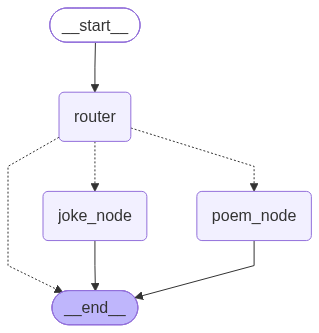

In [2]:
from typing import TypedDict, Literal
from collections.abc import Sequence
from langgraph.graph import StateGraph, START, END
from langgraph.types import Send,Command
from langchain.messages import HumanMessage
from langchain_deepseek import ChatDeepSeek
from langchain_openai import ChatOpenAI
import os
from rich import print as rprint
from dotenv import load_dotenv
# 从.env文件中加载环境变量
load_dotenv(override=True, verbose=True,dotenv_path="/Users/skk/Developer/lang-chain-learn/conf/.env")

OPENAI_API_KEY = os.environ["OPENAI_API_KEY"]
OPENAI_API_BASE = os.environ["OPENAI_API_BASE"]  # 与本项目 .env 中的名称一致
CONTENT_TYPES = ["poem", "ci_poem", "joke"]

model = ChatOpenAI(
    model="gpt-6-sol",  # 当前配置已验证可用；原 gpt-5.5 返回模型权限 403
    api_key=OPENAI_API_KEY,
    base_url=OPENAI_API_BASE,
)

class OverAllState(TypedDict):
    topic: str
    content_type: Literal["poem", "joke"]
    poem: str
    joke: str

class WorkerState(TypedDict):
    """
    私有状态，只对 Worker 节点可用
    """
    content_type: Literal["poem", "ci_poem", "joke"]
    prompt: str

class InputState(TypedDict):
    topic: str

class OutputState(TypedDict):
    poem: str
    ci_poem: str
    joke: str

def poem_node(state: OverAllState) -> OverAllState:
    topic = state["topic"]
    prompt = f"请生成一首关于 {topic} 的七言绝句"
    poem = model.invoke([HumanMessage(prompt)]).content

    return {
        "poem": poem
    }

def joke_node(state: OverAllState) -> OverAllState:
    topic = state["topic"]
    prompt = f"请生成一个关于 {topic} 的冷笑话"
    joke = model.invoke([HumanMessage(prompt)]).content

    return {
        "joke": joke
    }

def router(state: OverAllState) -> Command[Literal["poem_node", "joke_node", END]]:
    content_type = state["content_type"]

    if content_type == "poem":
        return Command (
            goto="poem_node"
        )
    elif content_type == "joke":
        return Command (
            goto="joke_node"
        )
    return Command (
        goto=END
    )
builder = StateGraph(state_schema=OverAllState)
builder.add_node("router", router)
builder.add_node("poem_node", poem_node)
builder.add_node("joke_node", joke_node)
builder.add_edge(START, "router")
builder.add_edge("poem_node", END)
builder.add_edge("joke_node", END)
# 添加了跳转节点到 poem_node 和 joke_node
builder.add_edge("router", "poem_node")
builder.add_edge("router", "joke_node")


graph = builder.compile()
res = graph.invoke({"topic": "秋天","content_type":"none"})
rprint(res)

from IPython.display import display
display(graph)

## 4.3 多分支汇聚：Fan-in


上文提到了**扇出（Fan-out）**，它是指像打开扇子一样，由一个上游节点分发出多个下游分支。

与之相对，**扇入（Fan-in）**是指像合拢扇子一样，多个上游分支汇聚到同一个下游节点。

**Fan-out** 对应的是“分支结构”，**Fan-in** 对应的是“多分支汇聚结构”。

### 4.3.1 静态扇入

当多个上游分支同时汇入同一个下游节点时，根据触发条件的不同，可以分成两种情况：

- **“与”**触发：上游所有分支全部到达才可触发下游节点
- **“或”**触发：任意一个分支到达，都可以触发下游节点

#### 4.3.1.1 **与**触发：等待所有上游分支到达
这是多分支汇聚中**最常见**的情况。

我们可以使用 节点执行步骤来观察，**`LangGraph`** 的计算图是在一系列超步中完成的，如果能看到每个节点实例运行时的超步编号，则节点执行顺序一目了然。

**`LangGraph`** 的节点可以通过名为 **`config`** 的有名参数获取运行时配置

```python
config["metadata"]["langgraph_step"]
```



2026-10-15 01:14:45.742 | INFO     | __main__:node_a:12 - cur_step: 1, node_a 被触发
2026-10-15 01:14:45.743 | INFO     | __main__:node_b:17 - cur_step: 2, node_b 被触发
2026-10-15 01:14:45.744 | INFO     | __main__:node_c:22 - cur_step: 2, node_c 被触发
2026-10-15 01:14:45.745 | INFO     | __main__:node_d:27 - cur_step: 3, node_d 被触发
2026-10-15 01:14:45.746 | INFO     | __main__:node_e:32 - cur_step: 4, node_e 被触发


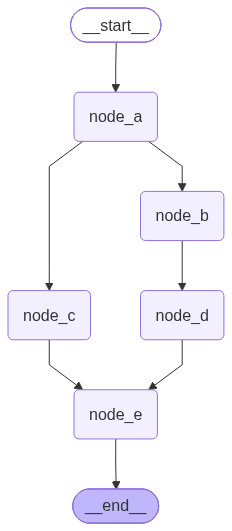

In [ ]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END
from langchain_core.runnables import RunnableConfig

from loguru import logger

class EmptyState(TypedDict):
    pass

def node_a(state: EmptyState, config: RunnableConfig) -> EmptyState:
    cur_step = config["metadata"]["langgraph_step"]
    logger.info("cur_step: {}, node_a 被触发", cur_step)
    return {}

def node_b(state: EmptyState, config: RunnableConfig) -> EmptyState:
    cur_step = config["metadata"]["langgraph_step"]
    logger.info("cur_step: {}, node_b 被触发", cur_step)
    return {}

def node_c(state: EmptyState, config: RunnableConfig) -> EmptyState:
    cur_step = config["metadata"]["langgraph_step"]
    logger.info("cur_step: {}, node_c 被触发", cur_step)
    return {}

def node_d(state: EmptyState, config: RunnableConfig) -> EmptyState:
    cur_step = config["metadata"]["langgraph_step"]
    logger.info("cur_step: {}, node_d 被触发", cur_step)
    return {}

def node_e(state: EmptyState, config: RunnableConfig) -> EmptyState:
    cur_step = config["metadata"]["langgraph_step"]
    logger.info("cur_step: {}, node_e 被触发", cur_step)
    return {}

builder = StateGraph(state_schema=EmptyState)
builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)
builder.add_node("node_c", node_c)
builder.add_node("node_d", node_d)
builder.add_node("node_e", node_e)

builder.add_edge(START, "node_a")
builder.add_edge("node_a", "node_b")
builder.add_edge("node_a", "node_c")
builder.add_edge("node_b", "node_d")
# 这里使用了列表作为节点
builder.add_edge(["node_c", "node_d"], "node_e")

graph = builder.compile()
graph.invoke({})

from IPython.display import display
display(graph)

####  4.3.1.2 **或**触发：任意上游分支到达即可触发

另一种情况是：多个上游分支分别连接到同一个下游节点，但它们之间没有显式的同步等待关系。

2026-10-15 01:28:57.584 | INFO     | __main__:node_a:12 - cur_step: 1, node_a 被触发
2026-10-15 01:28:57.585 | INFO     | __main__:node_b:17 - cur_step: 2, node_b 被触发
2026-10-15 01:28:57.586 | INFO     | __main__:node_c:22 - cur_step: 2, node_c 被触发
2026-10-15 01:28:57.588 | INFO     | __main__:node_d:27 - cur_step: 3, node_d 被触发
2026-10-15 01:28:57.588 | INFO     | __main__:node_e:32 - cur_step: 3, node_e 被触发
2026-10-15 01:28:57.589 | INFO     | __main__:node_e:32 - cur_step: 4, node_e 被触发


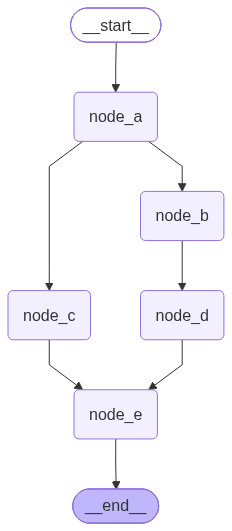

In [ ]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END
from langchain_core.runnables import RunnableConfig
from langgraph.types import Send,Command
from loguru import logger

class EmptyState(TypedDict):
    pass

def node_a(state: EmptyState, config: RunnableConfig) -> EmptyState:
    cur_step = config["metadata"]["langgraph_step"]
    logger.info("cur_step: {}, node_a 被触发", cur_step)
    return {}

def node_b(state: EmptyState, config: RunnableConfig) -> EmptyState:
    cur_step = config["metadata"]["langgraph_step"]
    logger.info("cur_step: {}, node_b 被触发", cur_step)
    return {}

def node_c(state: EmptyState, config: RunnableConfig) -> EmptyState:
    cur_step = config["metadata"]["langgraph_step"]
    logger.info("cur_step: {}, node_c 被触发", cur_step)
    return {}

def node_d(state: EmptyState, config: RunnableConfig) -> EmptyState:
    cur_step = config["metadata"]["langgraph_step"]
    logger.info("cur_step: {}, node_d 被触发", cur_step)
    return {}

def node_e(state: EmptyState, config: RunnableConfig) -> EmptyState:
    cur_step = config["metadata"]["langgraph_step"]
    logger.info("cur_step: {}, node_e 被触发", cur_step)
    return {}

builder = StateGraph(state_schema=EmptyState)
builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)
builder.add_node("node_c", node_c)
builder.add_node("node_d", node_d)
builder.add_node("node_e", node_e)

builder.add_edge(START, "node_a")
builder.add_edge("node_a", "node_b")
builder.add_edge("node_a", "node_c")
builder.add_edge("node_b", "node_d")
# builder.add_edge(["node_c", "node_d"], "node_e")
# 独立触发：node_c 完成后可以触发 node_e
builder.add_edge("node_c", "node_e")
# 独立触发：node_d 完成后可以触发 node_e
builder.add_edge("node_d", "node_e")

graph = builder.compile()
graph.invoke({})

from IPython.display import display
display(graph)

从运行结果可以看出，**`node_e`** 被触发了两次：

1. **`node_c`** 在第 2 个超步执行完成后，触发 **`node_e`** 在第 3 个超步执行；
2. **`node_d`** 在第 3 个超步执行完成后，再次触发 **`node_e`** 在第 4 个超步执行。

这种写法对应的是 **独立触发**

### 4.3.2 动态扇入-MapReduce结构

在上文我们通过 **`Send`** 动态生成了多个下游任务。

这种模式本质上是一种**动态扇出**：根据运行时数据，将一个任务拆分为多个子任务，并分别发送给下游节点处理。

如果这些子任务分别产生中间结果，并在后续通过 **`Reducer`** 进行合并，也就是重新 **扇入** 到一个下游节点中，最终得到统一的结果，那么就构成了典型的 **`MapReduce`** 结构。

> **`MapReduce`** 是大数据计算中的经典模型，通常包含两个核心阶段：
**`Map`：映射阶段**
将输入数据映射为中间结果。

在 **`LangGraph`** 中，可以理解为通过 **`Send`** 将子任务分发给多个 **`mapper`** 节点实例，每个节点实例独立完成局部计算：将部分输入数据映射为中间结果。

* 在 **`LangGraph`** 中，可以理解为通过 **`Send`** 将子任务分发给多个 **`mapper`** 节点实例，每个节点实例独立完成局部计算：将部分输入数据映射为中间结果。

* **`Reduce`：归约阶段**
  将多个子任务产生的中间结果进行汇总、合并或聚合，得到最终结果。

  在 **`LangGraph`** 中，通常由一个特定的 **`reducer`** 节点完成归约：它接收上游 **`mapper`** 节点实例产生的中间结果，处理后得到计算图的最终输出。


我们可以利用MapReduce完成分词统计的任务

2026-10-15 05:10:24.463 | INFO     | __main__:reducer_node:46 - reducer entries: [('hello', 1), ('world', 1), ('hello', 1), ('Atguigu', 1), ('hello', 1), ('LLM', 1)]
2026-10-15 05:10:24.463 | INFO     | __main__:reducer_node:50 - reducer shuffle entries: {'hello': 3, 'world': 1, 'Atguigu': 1, 'LLM': 1}


{
    'input_values': ['hello world', 'hello Atguigu', 'hello LLM'],
    'entries': [('hello', 1), ('world', 1), ('hello', 1), ('Atguigu', 1), ('hello', 1), ('LLM', 1)],
    'word_counts': {'hello': 3, 'world': 1, 'Atguigu': 1, 'LLM': 1}
}

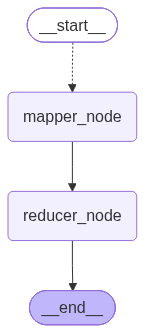

In [ ]:
from typing import TypedDict, Literal
from collections.abc import Sequence
from langgraph.graph import StateGraph, START, END
from langgraph.types import Send,Command
from langchain.messages import HumanMessage
from langchain_deepseek import ChatDeepSeek
from langchain_openai import ChatOpenAI
import os
from langgraph.types import Send,Command
from loguru import logger
from rich import print as rprint
from dotenv import load_dotenv
# 全局State
class OverAllState(TypedDict):
    input_values: list[str]
    entries: Annotated[list[tuple[str, int]], add]
    word_counts: dict[str, int]

# 意义?
class MaperInputState(TypedDict):
    input_value: str


def router_map(state: OverAllState) -> Sequence[Send]:
    input_value = state["input_values"]

    tasks = []
    for one_input_value in input_value:
        tasks.append(Send("mapper_node",{"input_value": one_input_value}))

    return tasks


def mapper_node(state: MaperInputState) -> OverAllState:
    input_values = state["input_value"]
    words = input_values.split(" ")
    entries = []
    for word in words:
        entries.append((word, 1))
        #entries.append({"word": word, "count": 1})

    return {"entries": entries}


def reducer_node(state: OverAllState) -> OverAllState:
    entries = state["entries"]
    logger.info("reducer entries: {}", entries)
    word_counts = {}
    for word,count in entries:
        word_counts[word] = word_counts.get(word, 0) + count
    logger.info("reducer shuffle entries: {}", word_counts)
    return {"word_counts": word_counts}


builder = StateGraph(state_schema=OverAllState)
builder.add_node("mapper_node", mapper_node)
builder.add_node("reducer_node", reducer_node)
builder.add_conditional_edges(START, router_map, path_map=["mapper_node"])
builder.add_edge("mapper_node", "reducer_node")
builder.add_edge("reducer_node", END)

graph = builder.compile()
word_counts = graph.invoke(
    {"input_values": [
        "hello world",
        "hello Atguigu",
        "hello LLM"
    ]}
)

rprint(word_counts)

from IPython.display import display
display(graph)

由于 **`entries`** 字段使用了 **`Reducer`**（**`LangGraph`** 状态的 **`Reducer`**，而不是当前示例中的 **`reducer_node`**）

```python
entries: Annotated[list[tuple[str, int]], add]
```

# 总结

### 1. 动态分支
动态分支有两类典型应用场景：
1. 动态扇出：**`Send`** + **`add_conditional_edges()`**
2. 动态跳转：Command(goto=...)

**`Send` 解决的是：运行时要启动多少个任务实例。**

**`Command(goto=...)` 解决的是：当前节点执行完后要去哪里。**

### 2. RunnableConfig 和 Runtime 区别

**一句话**：两者都是 LangGraph 运行时额外传给节点的信息，不属于 State，但用途不同：

- **`config: RunnableConfig`** 管"**这次运行怎么跑**"：运行设置、追踪信息，以及 LangGraph 写入的运行元数据（当前超步、当前节点等）。它来自 `langchain_core`，是一个普通 dict，模型、链和图都接受。
- **`runtime: Runtime[Context]`** 管"**这次运行要用到的依赖**"：自己定义的 context（如 user_id、用哪个模型），以及 store 等工具。它来自 `langgraph.runtime`，是 v0.6 新增的对象。

#### 2.1 对比

| | `config: RunnableConfig` | `runtime: Runtime[Context]` |
|---|---|---|
| 来自 | `langchain_core` | `langgraph.runtime`（v0.6 起） |
| 类型 | 普通 dict | 只读的 dataclass，`Context` 是泛型参数 |
| 调用时怎么传 | `invoke(..., config={...})` | `invoke(..., context=...)`；store 在 `compile(store=...)` 时传 |
| 有没有类型约束 | `configurable` 是 `dict[str, Any]`，键名写错不会报错 | `context` 的结构由 `context_schema` 规定 |
| 适用范围 | 所有 Runnable：模型、链、图 | 只有 LangGraph 图，以及基于图实现的 Agent 和中间件 |
| 适合放什么 | 观察或控制运行过程：超步号、节点名、`recursion_limit`、`thread_id`、追踪用的 tags | 业务依赖：谁在调用（user_id）、用哪个模型、连哪个数据库；store；自定义流式输出 |

v0.6 之前，user_id 这类业务参数通常放在 `config["configurable"]` 里，图上用 `config_schema` 声明。现在 `config_schema` 已弃用，改用 `context_schema`。

#### 2.2 config 里有什么

用 `config={"configurable": {"thread_id": "t1", "model": "deepseek"}, "tags": ["demo"], "recursion_limit": 50}` 调用，节点内打印（见下方实验 cell）：

```text
type(config)    = dict
metadata        = {'langgraph_step': 1, 'langgraph_node': 'show_node',
                   'langgraph_triggers': ('branch:to:show_node',), 'thread_id': 't1', ...}
configurable    = {'thread_id': 't1', 'model': 'deepseek', 'checkpoint_id': None, ...}  另有若干 __pregel_* 内部键
recursion_limit = 50,  tags = ['demo'],  callbacks = ...
```

- **`metadata`**：LangGraph 在每个节点运行前写入的运行信息。本节用的 `langgraph_step` 就在这里；`langgraph_triggers` 是触发该节点的 channel（见 02 笔记总结第 2 节）。
- **`configurable`**：调用方传入的任意键值，例如 `thread_id`。LangGraph 的内部数据（`__pregel_*` 键）也放在这里。
- **`recursion_limit`、`tags`、`callbacks`**：所有 Runnable 通用的运行设置和追踪设置，所以 `model.invoke(..., config=...)` 也能传它们。

#### 2.3 runtime 里有什么

图上声明 `context_schema=Ctx`，调用时传 `context=Ctx(user_id="u_42")`，节点内打印：

```text
runtime.context        = Ctx(user_id='u_42')     ← 类型由 context_schema 决定
runtime.execution_info = thread_id / task_id / node_attempt ...
runtime.store          = None                    ← compile(store=...) 时才有，用于长期记忆
runtime.stream_writer                            ← 自定义流式输出
修改 runtime.context   → FrozenInstanceError     ← 只读
```

`execution_info` 里**没有超步号**，所以观察超步只能读 `config["metadata"]["langgraph_step"]`。

#### 2.4 注入规则：按参数名，不按类型

节点函数的第一个参数是 state，之后的参数按**参数名**注入：

- 名为 `config`：注入 RunnableConfig。类型注解只能是 `RunnableConfig` 或不写，写成别的类型会收到警告。
- 名为 `runtime`：注入 Runtime，类型注解随意。
- 另外还能按名字注入 `writer`、`store`、`previous`。

参数写成 `cfg: RunnableConfig` 不会被注入，运行时报 `TypeError: ... missing 1 required positional argument: 'cfg'`。

#### 2.5 和中间件里的 `Runtime[Context]` 的关系

两者是**同一个类** `langgraph.runtime.Runtime`。`create_agent` 会把每个中间件钩子变成 Agent 图里的一个节点（实验中 `before_model` 钩子对应的节点名是 `show_hook.before_model`），所以钩子拿到 runtime 的方式和普通节点完全一样。

区别在于钩子的签名固定为 `(state, runtime)`，没有 `config` 参数。中间件里需要 config 时，用 `from langgraph.config import get_config`，再调用 `get_config()`。

In [ ]:
# 实验：查看 config 和 runtime 的内容、注入规则，以及中间件拿到的 runtime（不调用真实模型）
from dataclasses import dataclass
from typing import TypedDict
from langchain_core.runnables import RunnableConfig
from langgraph.graph import StateGraph, START
from langgraph.runtime import Runtime
from langgraph.checkpoint.memory import InMemorySaver

class DemoState(TypedDict):
    x: int

@dataclass
class Ctx:
    user_id: str

def show_node(state: DemoState, config: RunnableConfig, runtime: Runtime[Ctx]):
    print("== config ==")
    print("type:", type(config).__name__, "| keys:", sorted(config))
    print("metadata:", {k: v for k, v in config["metadata"].items() if not k.startswith("__")})
    print("configurable:", {k: v for k, v in config["configurable"].items() if not k.startswith("__")})
    print("recursion_limit:", config["recursion_limit"], "| tags:", config["tags"])
    print("== runtime ==")
    print("context:", runtime.context)
    info = runtime.execution_info
    print("execution_info:", {"thread_id": info.thread_id, "task_id": info.task_id, "node_attempt": info.node_attempt})
    print("store:", runtime.store)
    try:
        runtime.context = Ctx("other")
    except Exception as e:
        print("修改 runtime.context ->", type(e).__name__)
    return {}

builder = StateGraph(DemoState, context_schema=Ctx)
builder.add_node("show_node", show_node)
builder.add_edge(START, "show_node")
builder.compile(checkpointer=InMemorySaver()).invoke(
    {"x": 0},
    config={"configurable": {"thread_id": "t1", "model": "deepseek"}, "tags": ["demo"], "recursion_limit": 50},
    context=Ctx(user_id="u_42"),
)

print("\n== 参数名不是 config 时不会注入 ==")
def renamed_node(state: DemoState, cfg: RunnableConfig):  # ← 改动：参数名为 cfg
    return {}
builder = StateGraph(DemoState)
builder.add_node("renamed_node", renamed_node)
builder.add_edge(START, "renamed_node")
try:
    builder.compile().invoke({"x": 0})
except TypeError as e:
    print("TypeError:", e)

print("\n== 中间件钩子拿到的 runtime ==")
from langchain.agents import create_agent
from langchain.agents.middleware import before_model
from langchain_core.language_models.fake_chat_models import GenericFakeChatModel
from langchain.messages import AIMessage
from langgraph.config import get_config

@before_model
def show_hook(state, runtime: Runtime[Ctx]):
    print("runtime 的类:", f"{type(runtime).__module__}.{type(runtime).__name__}")
    print("runtime.context:", runtime.context)
    print("get_config() 读到的节点名:", get_config()["metadata"]["langgraph_node"])
    return None

fake_model = GenericFakeChatModel(messages=iter([AIMessage("hi")]))
agent = create_agent(fake_model, tools=[], middleware=[show_hook], context_schema=Ctx)
agent.invoke({"messages": [("user", "hello")]}, context=Ctx(user_id="u_42"))

# 问题

### 1. Send 的 args 参数一定是dict吗?